In [23]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
from sklearn.model_selection import RepeatedStratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt


train_set =pd.read_csv('train.csv')
test_set = pd.read_csv('test.csv')

X = train_set.drop(columns=["id", "target"]).values.astype(np.float32)
y = train_set["target"].values

print(X)
print(y)


[[5.5 2.4 3.7 1. ]
 [6.3 2.8 5.1 1.5]
 [6.4 3.1 5.5 1.8]
 [6.6 3.  4.4 1.4]
 [7.2 3.6 6.1 2.5]
 [5.7 2.9 4.2 1.3]
 [7.6 3.  6.6 2.1]
 [5.6 3.  4.5 1.5]
 [5.1 3.5 1.4 0.2]
 [7.7 2.8 6.7 2. ]
 [5.8 2.7 4.1 1. ]
 [5.2 3.4 1.4 0.2]
 [5.  3.5 1.3 0.3]
 [5.1 3.8 1.9 0.4]
 [5.  2.  3.5 1. ]
 [6.3 2.7 4.9 1.8]
 [4.8 3.4 1.9 0.2]
 [5.  3.  1.6 0.2]
 [5.1 3.3 1.7 0.5]
 [5.6 2.7 4.2 1.3]
 [5.1 3.4 1.5 0.2]
 [5.7 3.  4.2 1.2]
 [7.7 3.8 6.7 2.2]
 [4.6 3.2 1.4 0.2]
 [6.2 2.9 4.3 1.3]
 [5.7 2.5 5.  2. ]
 [5.5 4.2 1.4 0.2]
 [6.  3.  4.8 1.8]
 [5.8 2.7 5.1 1.9]
 [6.  2.2 4.  1. ]
 [5.4 3.  4.5 1.5]
 [6.2 3.4 5.4 2.3]
 [5.5 2.3 4.  1.3]
 [5.4 3.9 1.7 0.4]
 [5.  2.3 3.3 1. ]
 [6.4 2.7 5.3 1.9]
 [5.  3.3 1.4 0.2]
 [5.  3.2 1.2 0.2]
 [5.5 2.4 3.8 1.1]
 [6.7 3.  5.  1.7]
 [4.9 3.1 1.5 0.2]
 [5.8 2.8 5.1 2.4]
 [5.  3.4 1.5 0.2]
 [5.  3.5 1.6 0.6]
 [5.9 3.2 4.8 1.8]
 [5.1 2.5 3.  1.1]
 [6.9 3.2 5.7 2.3]
 [6.  2.7 5.1 1.6]
 [6.1 2.6 5.6 1.4]
 [7.7 3.  6.1 2.3]
 [5.5 2.5 4.  1.3]
 [4.4 2.9 1.4 0.2]
 [4.3 3.  1.

In [24]:
device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")

print(f"Using device: {device}")

X_tr, X_va, y_tr, y_va = train_test_split(X, y, test_size=0.2, stratify=y, random_state=0)
scaler = StandardScaler().fit(X_tr)
X_tr = torch.tensor(scaler.transform(X_tr), device=device)
X_va = torch.tensor(scaler.transform(X_va), device=device)
y_tr = torch.tensor(y_tr, device=device)
y_va = torch.tensor(y_va, device=device)

Using device: mps


In [25]:
# Define model

class SimpleMLP(nn.Module):

    def __init__(self, hidden):
        super().__init__()
        self.fc1 = nn.Linear(4, hidden)
        self.fc2 = nn.Linear(hidden, 3)

    def forward(self, x):
        return self.fc2(torch.relu(self.fc1(x)))

def train_model(X, y, hidden, weight_decay, lr=1e-2, epochs=85):  
    torch.manual_seed(0)
    model = SimpleMLP(hidden).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    X_tensor = torch.tensor(X, device=device)
    y_tensor = torch.tensor(y, device=device)

    for i in range(epochs):
        optimizer.zero_grad()
        loss = nn.functional.cross_entropy(model(X_tensor), y_tensor)
        loss.backward()
        optimizer.step()
    return model

def predict(model, X):
    with torch.no_grad():
        X_tensor = torch.tensor(X, device=device)
        return model(X_tensor).argmax(dim=1).cpu().numpy()


In [26]:
cv = RepeatedStratifiedKFold(n_splits=10, n_repeats=3, random_state=0)
results = {}

for hidden in [4, 8, 16, 32]:
    for wd in [0, 1e-4, 1e-3, 1e-2]:
        for epochs in [50, 100, 200, 400]:
            accs = []
            for tr, va in cv.split(X, y):
                scaler = StandardScaler().fit(X[tr])
                model = train_model(scaler.transform(X[tr]), y[tr], hidden, wd, epochs=epochs)
                accs.append(np.mean(predict(model, scaler.transform(X[va])) == y[va]))
            results[(hidden, wd, epochs)] = np.mean(accs)
            print(f"hidden={hidden:2d}  wd={wd:g}  epochs={epochs:3d}  acc={results[(hidden, wd, epochs)]:.3f}")

# Configs within 1% (~1 flower) of the best are tied: pick the smallest model, then the fewest epochs
best_acc = max(results.values())
tied = [k for k, acc in results.items() if acc >= best_acc - 0.01]
best_hidden, best_wd, best_epochs = min(tied, key=lambda k: (k[0], k[2]))
print(f"\nBest acc {best_acc:.3f}, {len(tied)} configs tied within 1%")
print(f"Chosen: hidden={best_hidden}  wd={best_wd:g}  epochs={best_epochs}  acc={results[(best_hidden, best_wd, best_epochs)]:.3f}")

hidden= 4  wd=0  epochs= 50  acc=0.647
hidden= 4  wd=0  epochs=100  acc=0.641
hidden= 4  wd=0  epochs=200  acc=0.930
hidden= 4  wd=0  epochs=400  acc=0.956
hidden= 4  wd=0.0001  epochs= 50  acc=0.647
hidden= 4  wd=0.0001  epochs=100  acc=0.641
hidden= 4  wd=0.0001  epochs=200  acc=0.930
hidden= 4  wd=0.0001  epochs=400  acc=0.956
hidden= 4  wd=0.001  epochs= 50  acc=0.647
hidden= 4  wd=0.001  epochs=100  acc=0.641
hidden= 4  wd=0.001  epochs=200  acc=0.930
hidden= 4  wd=0.001  epochs=400  acc=0.956
hidden= 4  wd=0.01  epochs= 50  acc=0.647
hidden= 4  wd=0.01  epochs=100  acc=0.644
hidden= 4  wd=0.01  epochs=200  acc=0.930
hidden= 4  wd=0.01  epochs=400  acc=0.949
hidden= 8  wd=0  epochs= 50  acc=0.851
hidden= 8  wd=0  epochs=100  acc=0.914
hidden= 8  wd=0  epochs=200  acc=0.927
hidden= 8  wd=0  epochs=400  acc=0.930
hidden= 8  wd=0.0001  epochs= 50  acc=0.851
hidden= 8  wd=0.0001  epochs=100  acc=0.914
hidden= 8  wd=0.0001  epochs=200  acc=0.927
hidden= 8  wd=0.0001  epochs=400  acc=0.

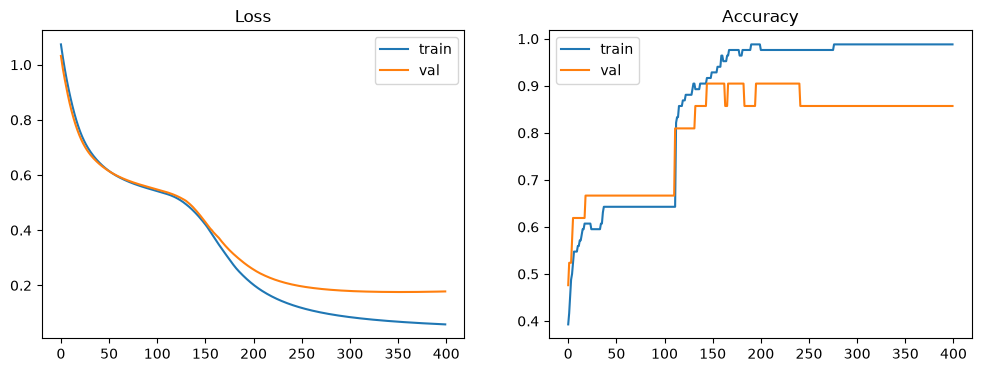

Train: loss 0.059  acc 0.988
Val:   loss 0.178  acc 0.857


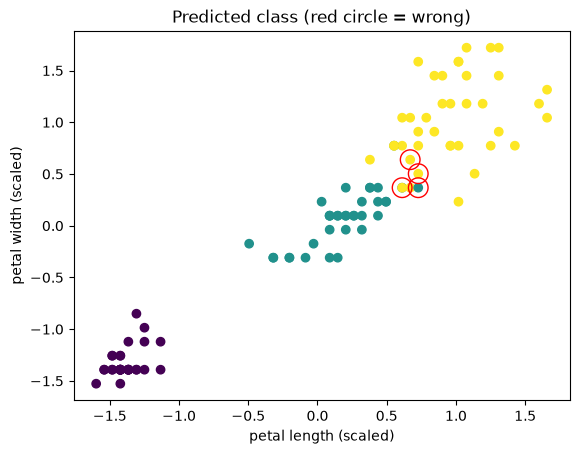

In [28]:
torch.manual_seed(0)
model = SimpleMLP(best_hidden).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-2, weight_decay=best_wd)
train_loss, val_loss, train_acc, val_acc = [], [], [], []

for epoch in range(best_epochs):
    optimizer.zero_grad()
    out = model(X_tr)
    loss = nn.functional.cross_entropy(out, y_tr)
    loss.backward()
    optimizer.step()

    with torch.no_grad():
        out_va = model(X_va)
        train_loss.append(loss.item())
        val_loss.append(nn.functional.cross_entropy(out_va, y_va).item())
        train_acc.append((out.argmax(1) == y_tr).float().mean().item())
        val_acc.append((out_va.argmax(1) == y_va).float().mean().item())

# Learning curves
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(train_loss, label="train"); plt.plot(val_loss, label="val"); plt.title("Loss"); plt.legend()
plt.subplot(1, 2, 2)
plt.plot(train_acc, label="train"); plt.plot(val_acc, label="val"); plt.title("Accuracy"); plt.legend()
plt.show()
print(f"Train: loss {train_loss[-1]:.3f}  acc {train_acc[-1]:.3f}")
print(f"Val:   loss {val_loss[-1]:.3f}  acc {val_acc[-1]:.3f}")

# Class separation (petal length vs petal width, scaled)
X_all = torch.cat([X_tr, X_va])
y_all = torch.cat([y_tr, y_va]).cpu()
with torch.no_grad():
    pred = model(X_all).argmax(1).cpu()
X_all = X_all.cpu()
wrong = pred != y_all
plt.scatter(X_all[:, 2], X_all[:, 3], c=pred)
plt.scatter(X_all[wrong, 2], X_all[wrong, 3], s=200, facecolors="none", edgecolors="red")
plt.xlabel("petal length (scaled)"); plt.ylabel("petal width (scaled)"); plt.title("Predicted class (red circle = wrong)")
plt.show()


In [29]:
# Predict on the test set: retrain the chosen config on all 105 training rows
X_test = test_set.drop(columns=["id"]).values.astype(np.float32)

scaler = StandardScaler().fit(X)
model = train_model(scaler.transform(X), y, best_hidden, best_wd, epochs=best_epochs)
test_pred = predict(model, scaler.transform(X_test))

submission = pd.DataFrame({"id": test_set["id"], "target": test_pred})
submission.to_csv("submission_nn.csv", index=False)
print(submission["target"].value_counts().sort_index())

target
0    19
1    13
2    13
Name: count, dtype: int64
